# Lab 11 — Complementary filter for the robot course (digits 9 1)

Same robot, trajectory, controller and gains as Lab 10. Only the course line changes:

```
course = K · (course + gyro_inc) + (1 − K) · course_odom          τ = K · dt / (1 − K)
```

| Run | `K` (gyro) | `1 − K` (odometry) | log |
|---|---|---|---|
| 1 | 0.98 | 0.02 | `cf_098.txt` |
| 2 | 0.5 | 0.5 | `cf_050.txt` |
| 3 | 0.02 | 0.98 | `cf_002.txt` |
| check | 1 (motors off, 60 s) | 0 | `cf_cal.txt` |

In every run the robot was **held for ≈ 3 s and turned by ≈ 45° by hand** on the first long straight (segment 1, the stem
of the 9). Log: `t, ts, i, encL, encR, gz, bias, course, course_odom, course_g, x, y, pL, pR` with a header
`# K TEST b0 sd ncal nrej T_CAL r B s GS TICK`. `gz` and the encoders are raw, so any course can be recomputed offline.

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

SIM = False          # True: 2D-model logs (ideal gyro, nobody can grab the robot) to test the notebook
PRE = 'cf_sim_' if SIM else 'cf_'
LOGS = {0.98: PRE + '098.txt', 0.5: PRE + '050.txt', 0.02: PRE + '002.txt'}
CAL = PRE + 'cal.txt'
# hand disturbance (s since the log starts): from the partner / video; None = detect from the log
DISTURB = {0.98: None, 0.5: None, 0.02: None}
# what the robot did after it was let go (from watching / the video)
BEHAVIOUR = {0.98: 'held: wheels slipped (encoders -237 deg, gyro +32 deg); after release the estimate slid to the false encoder course in ~4 s; twisted "91", ~38 cm off', 0.5: 'estimate = encoders (tau < one loop); encoders caught up 0.5 s after release, ~10 deg left; rest of the "91" close (7 cm max)', 0.02: 'estimate = encoders; ~37 deg of the hand turn never seen; the "1" drawn rotated, 20 cm max, end 10 cm off'}
# real end pose measured with a tape (axle midpoint, start frame), cm and deg; None if not measured
END_MEAS = {0.98: None, 0.5: None, 0.02: None}

X_ref = np.array([0, 0, -30, -30, 0, 30, 30, 21.5])    # waypoints "91", cm
Y_ref = np.array([0, 60, 60, 30, 30, 0, 60, 51.5])
NSEG = len(X_ref) - 1
wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi
raw = np.arctan2(np.diff(Y_ref), np.diff(X_ref))
course_ref = np.zeros(NSEG); prev = 0.0
for k in range(NSEG):
    prev = course_ref[k] = prev + wrap(raw[k] - prev)

def load(fn):
    try:
        head = open(fn).readline()
    except FileNotFoundError:                       # Colab: upload the logs
        from google.colab import files
        files.upload(); head = open(fn).readline()
    meta = {k: float(v) for k, v in re.findall(r'(\w+)=([-+\d.eE]+)', head)}
    df = pd.read_csv(fn, comment='#')
    df['t_s'] = df.t / 1000
    return df, meta

## Step 1 — Gyro calibration and the 60-s check

**My calibration (on the robot, block diagram).** The robot stands still for `T_CAL = 10 s` (Lab 9: the `b0(T)` curve is
flat from 10 s). First 3 s: plain mean `m1` and standard deviation `sd1` of `gz`. Remaining 7 s: mean of only the samples
within `m1 ± 4·sd1` → `b0`. A bump or a spike cannot move it (Lab 9's idea: robust statistics, outlier cut).
`s` (+0.16 %) and the sign (CCW positive, `GS = 1`) come from Lab 9; `read()[2]` is already in mdeg/s.

**Check.** `TEST = 1`: motors off, `K = 1`, 60 s still after the calibration. Course drift must be below 1 °/min.

{'b0': 0.0695770308123249, 'sd': 0.05550847367324125, 'ncal': 357.0, 'nrej': 0.0, 'T_CAL': 10.0}


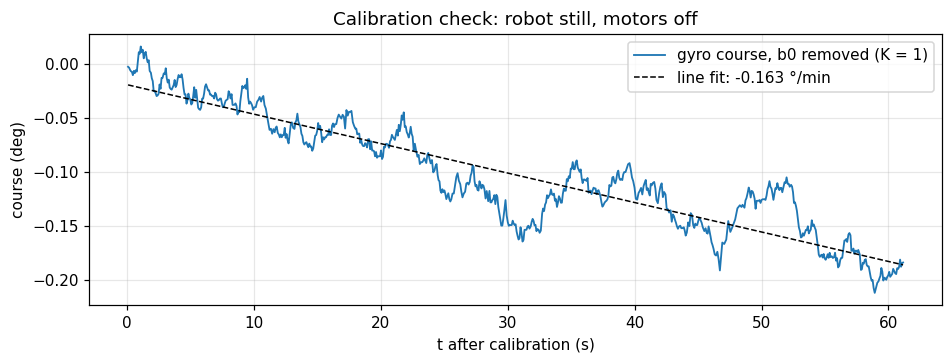

course after 60 s: -0.195 deg  ->  drift -0.163 deg/min  ->  PASS (< 1 deg/min)


In [2]:
cal, mc = load(CAL)
print({k: mc[k] for k in ('b0', 'sd', 'ncal', 'nrej', 'T_CAL') if k in mc})
tc = cal.t_s.values; cg = np.degrees(cal.course_g.values)
slope = np.polyfit(tc / 60, cg, 1)[0]
end60 = np.interp(60, tc, cg)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(tc, cg, lw=1.2, label='gyro course, b0 removed (K = 1)')
ax.plot(tc, np.polyval(np.polyfit(tc / 60, cg, 1), tc / 60), 'k--', lw=1, label=f'line fit: {slope:+.3f} °/min')
ax.set_xlabel('t after calibration (s)'); ax.set_ylabel('course (deg)'); ax.legend(); ax.set_title('Calibration check: robot still, motors off')
plt.show()
print(f'course after 60 s: {end60:+.3f} deg  ->  drift {slope:+.3f} deg/min  ->  {"PASS (< 1 deg/min)" if abs(slope) < 1 else "FAIL"}')

## Loop period `dt` and the time constant `τ`

`τ = K·dt/(1 − K)`: rotations faster than `τ` come from the gyro, slower changes are pulled back to `course_odom`.

In [3]:
D = {K: load(fn) for K, fn in LOGS.items()}
rows = []
for K, (df, m) in D.items():
    dts = np.diff(df.t_s.values); dtg = np.diff(df.ts.values) * m['TICK']
    dt = np.median(dts)
    rows.append([K, m['b0'], 1000 * dt, 1000 * dts.std(), 1000 * dts.max(), K * dt / (1 - K), df.t_s.iloc[-1]])
TAU = pd.DataFrame(rows, columns=['K', 'b0 (deg/s)', 'dt median (ms)', 'dt std (ms)', 'dt max (ms)', 'tau (s)', 'run length (s)'])
print(TAU.round(4).to_string(index=False))
DT = TAU['dt median (ms)'].mean() / 1000
print(f'\nwith dt = {1000*DT:.0f} ms: K = 0.98 -> tau = {0.98*DT/0.02:.2f} s,  K = 0.5 -> {0.5*DT/0.5*1000:.0f} ms,  K = 0.02 -> {0.02*DT/0.98*1000:.2f} ms')

   K  b0 (deg/s)  dt median (ms)  dt std (ms)  dt max (ms)  tau (s)  run length (s)
0.98      0.0335            78.0      10.1826        131.0   3.8220          25.208
0.50      0.0271            78.0       9.8025        119.0   0.0780          24.102
0.02      0.0168            78.0      10.3832        132.0   0.0016          27.123

with dt = 78 ms: K = 0.98 -> tau = 3.82 s,  K = 0.5 -> 78 ms,  K = 0.02 -> 1.59 ms


## Step 4.1 — Reconstruct three courses from each log

In [4]:
def courses(df, m, K):
    thl, thr = np.radians(df.encL.values), np.radians(df.encR.values)
    path = (thr + thl) * m['r'] / 2
    c_odom = (thr - thl) * m['r'] / m['B']
    dt = np.diff(df.ts.values, prepend=df.ts.values[0]) * m['TICK']
    ginc = m['GS'] * (df.gz.values / 1000 - m['b0']) / (1 + m['s']) * dt * np.pi / 180
    c_gyro = np.cumsum(ginc)
    c = np.zeros(len(df)); prev = 0.0
    for k in range(len(df)):
        prev = c[k] = K * (prev + ginc[k]) + (1 - K) * c_odom[k]
    return pd.DataFrame({'path': path, 'course_odom': c_odom, 'course_gyro': c_gyro, 'course': c})

def xy(path, course):
    dp = np.diff(path, prepend=0.0)
    return np.cumsum(dp * np.cos(course)), np.cumsum(dp * np.sin(course))

R = {K: courses(df, m, K) for K, (df, m) in D.items()}
for K, (df, m) in D.items():
    r = R[K]
    print(f'K = {K:<4}: max |course recomputed − logged| = {np.degrees(np.abs(r.course - df.course)).max():.2f} deg,'
          f' |course_odom| {np.degrees(np.abs(r.course_odom - df.course_odom)).max():.2f} deg,'
          f' |course_gyro| {np.degrees(np.abs(r.course_gyro - df.course_g)).max():.2f} deg')

K = 0.98: max |course recomputed − logged| = 1.05 deg, |course_odom| 3.90 deg, |course_gyro| 0.00 deg
K = 0.5 : max |course recomputed − logged| = 3.78 deg, |course_odom| 4.11 deg, |course_gyro| 0.00 deg
K = 0.02: max |course recomputed − logged| = 4.93 deg, |course_odom| 4.98 deg, |course_gyro| 0.00 deg


### Where was the hand disturbance?

The hand turn rotates the robot, but the held wheels do not follow, so `course_gyro − course_odom` jumps. The detector looks
for the largest change of that gap within 4 s; `DISTURB` (from the partner's timing / the video) overrides it.

In [5]:
def detect(df, r, win=4.0, thr=15, h=0.25):
    t = df.t_s.values; g = np.degrees(r.course_gyro - r.course_odom).values
    j = np.searchsorted(t, t + win).clip(0, len(t) - 1)
    jump = g[j] - g
    a = int(np.argmax(np.abs(jump)))
    if abs(jump[a]) < thr:
        return None
    # rate of the gap over +-h s (the encoder course is quantised, a 1-sample derivative is all spikes)
    lo, hi = np.searchsorted(t, t - h).clip(0, len(t) - 1), np.searchsorted(t, t + h).clip(0, len(t) - 1)
    rate = np.abs(g[hi] - g[lo]) / np.maximum(t[hi] - t[lo], 1e-3)
    seg = np.arange(a, j[a] + 1)
    on = seg[rate[seg] > 0.25 * rate[seg].max()]
    return float(t[on[0]] - h), float(t[on[-1]] + h)

DIS = {}
for K, (df, m) in D.items():
    DIS[K] = DISTURB[K] or detect(df, R[K])
    src = 'manual' if DISTURB[K] else 'detected'
    print(f'K = {K:<4}: disturbance ' + (f'{DIS[K][0]:.1f} – {DIS[K][1]:.1f} s ({src})' if DIS[K] else 'not found'))

K = 0.98: disturbance 2.5 – 4.7 s (detected)
K = 0.5 : disturbance 3.4 – 4.6 s (detected)
K = 0.02: disturbance 3.3 – 5.0 s (detected)


## Step 4.2 — Course plots

For each run: `course_odom`, `course_gyro` and the filtered `course`, disturbance shaded.

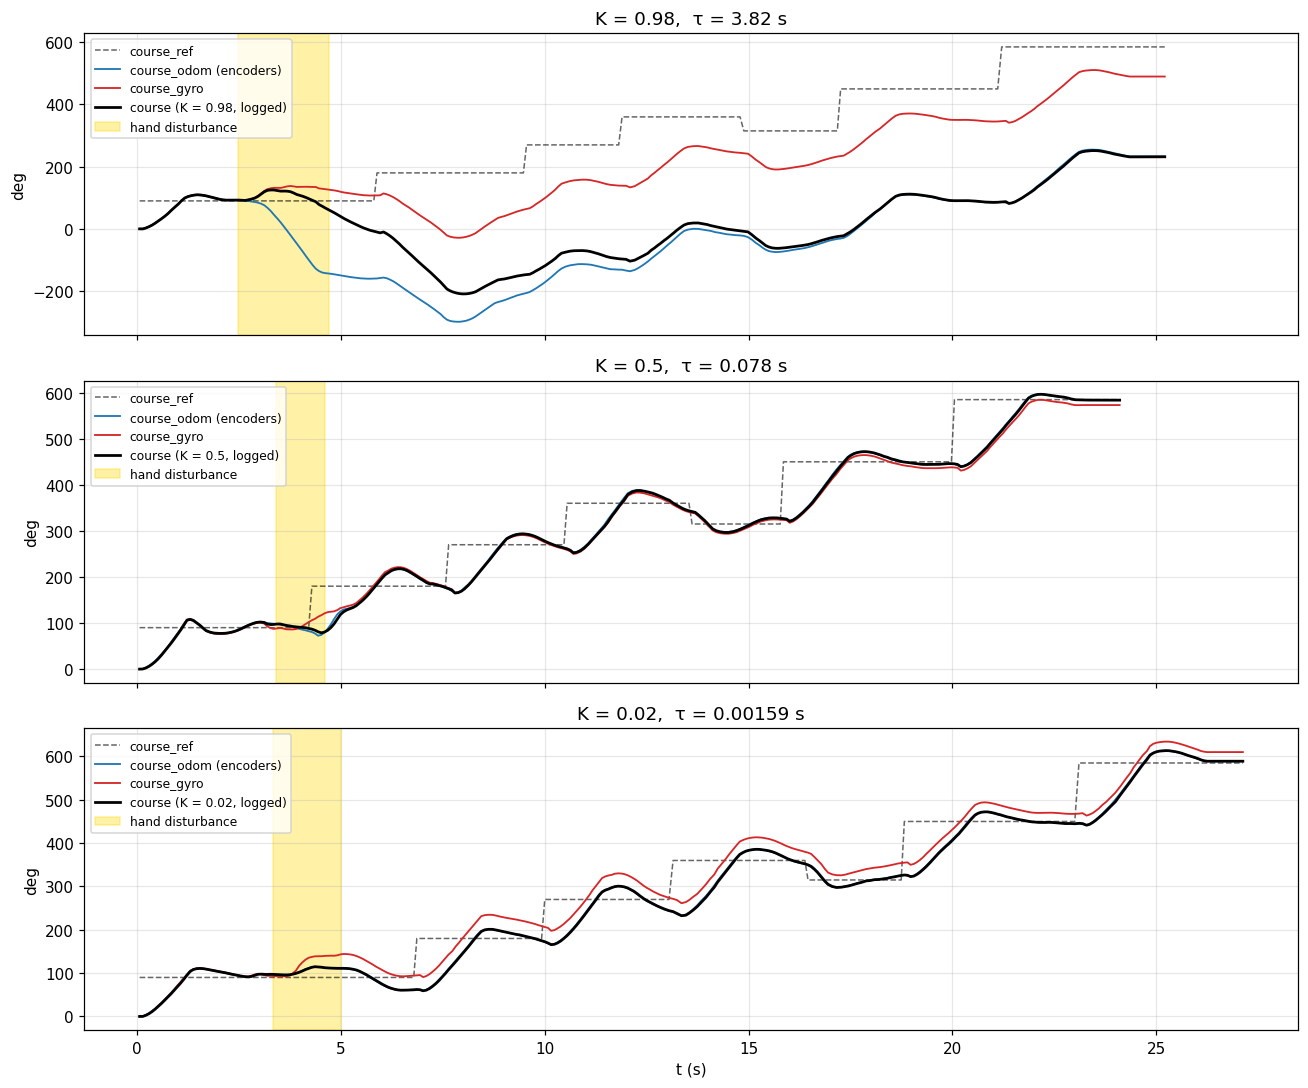

In [6]:
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (K, (df, m)) in zip(axs, D.items()):
    r = R[K]; t = df.t_s
    stair = np.degrees(course_ref[np.clip(df.i.values, 1, NSEG) - 1])
    ax.plot(t, stair, color='k', ls='--', lw=1, alpha=.6, label='course_ref')
    ax.plot(t, np.degrees(r.course_odom), color='tab:blue', lw=1.2, label='course_odom (encoders)')
    ax.plot(t, np.degrees(r.course_gyro), color='tab:red', lw=1.2, label='course_gyro')
    ax.plot(t, np.degrees(df.course), color='k', lw=1.8, label=f'course (K = {K}, logged)')
    if DIS[K]:
        ax.axvspan(*DIS[K], color='gold', alpha=.35, label='hand disturbance')
    ax.set_ylabel('deg'); ax.set_title(f'K = {K},  τ = {K * DT / (1 - K):.3g} s'); ax.legend(fontsize=8, loc='upper left')
axs[-1].set_xlabel('t (s)'); plt.tight_layout(); plt.show()

In [7]:
def memory(t, gap, b):
    # peak of |gap| within 2 s from b, and the time from that peak until |gap| < peak/e
    w = np.flatnonzero(t[b:] - t[b] < 2.0) + b
    p = w[np.argmax(np.abs(gap[w]))]
    g0 = gap[p]
    below = np.flatnonzero(np.abs(gap[p:]) < abs(g0) / np.e) if abs(g0) > 0.5 else []
    return g0, (t[p + below[0]] - t[p] if len(below) else np.nan), p

def response(df, r, dis, K):
    if not dis: return [np.nan] * 5
    t = df.t_s.values; a, b = np.searchsorted(t, dis).clip(0, len(t) - 1)
    jg = np.degrees(r.course_gyro.values[b] - r.course_gyro.values[a])
    jo = np.degrees(r.course_odom.values[b] - r.course_odom.values[a])
    gap = np.degrees(df.course.values - r.course_odom.values)          # what the filter still remembers
    g0, t_ret, _ = memory(t, gap, a)
    return [jg, jo, jg - jo, g0, t_ret]
RESP = pd.DataFrame([[K, K * DT / (1 - K), *response(D[K][0], R[K], DIS[K], K)] for K in D],
                    columns=['K', 'tau (s)', 'Δ course_gyro (deg)', 'Δ course_odom (deg)', 'seen by gyro only (deg)',
                             'max course − course_odom (deg)', 'decay to 1/e (s)'])
print(RESP.round(3).to_string(index=False))

   K  tau (s)  Δ course_gyro (deg)  Δ course_odom (deg)  seen by gyro only (deg)  max course − course_odom (deg)  decay to 1/e (s)
0.98    3.822               31.675             -237.062                  268.737                         215.312             3.998
0.50    0.078               35.528              -10.175                   45.703                         -10.392             0.316
0.02    0.002               51.047               14.289                   36.758                          -0.984             0.311


## Step 4.3 — Trajectories

Solid: the robot's own estimate (filtered course — what the controller believed). Dotted: the same log with the **gyro**
course, the best guess of where the robot really went (it sees the hand turn; the path still comes from the wheels, which
slipped while held).

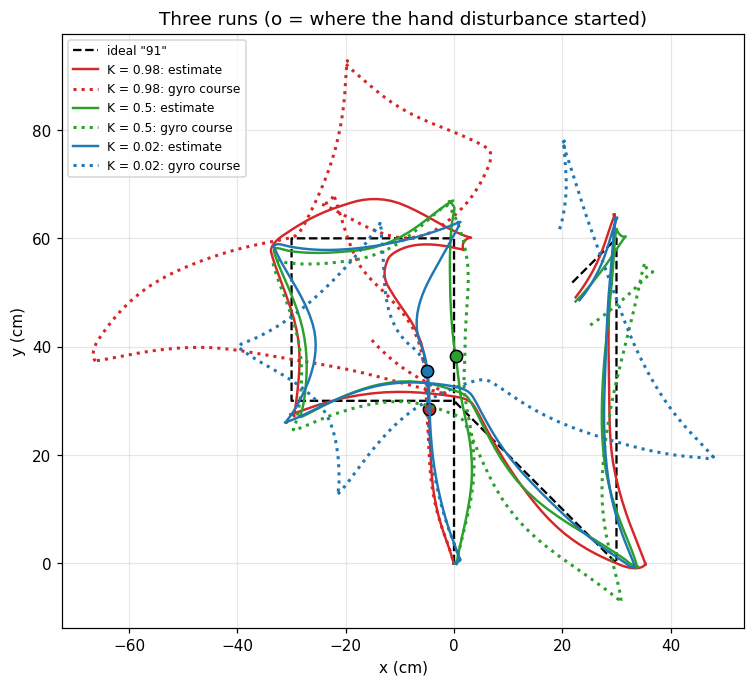

In [8]:
colK = {0.98: 'tab:red', 0.5: 'tab:green', 0.02: 'tab:blue'}
P = {}
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(X_ref, Y_ref, 'k--', lw=1.5, label='ideal "91"')
for K, (df, m) in D.items():
    r = R[K]
    xg, yg = xy(r.path.values, r.course_gyro.values)
    P[K] = {'est': (df.x.values, df.y.values, df.course.values), 'gyro': (xg, yg, r.course_gyro.values)}
    ax.plot(df.x, df.y, color=colK[K], lw=1.6, label=f'K = {K}: estimate')
    ax.plot(xg, yg, ':', color=colK[K], lw=2, label=f'K = {K}: gyro course')
    if DIS[K]:
        a = np.searchsorted(df.t_s.values, DIS[K][0])
        ax.plot(df.x.values[a], df.y.values[a], 'o', color=colK[K], mec='k', ms=8)
    if END_MEAS.get(K):
        ax.plot(*END_MEAS[K][:2], 'X', color=colK[K], mec='k', ms=12, label=f'K = {K}: tape-measured end')
ax.set_aspect('equal'); ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)'); ax.legend(fontsize=8, loc='best')
ax.set_title('Three runs (o = where the hand disturbance started)'); plt.show()

## Step 4.4 — Comparison with the ideal trajectory

As in Labs 6–7: `distance` = shortest distance from (x, y) to the ideal trajectory, `courseAngle` = course − `course_ref`
of the current segment (wrapped). Computed on the **gyro-course** reconstruction (closest to what happened) and, for
reference, on the robot's own estimate.

In [9]:
def dist_to_polyline(x, y):
    best = np.full(len(x), np.inf)
    for k in range(NSEG):
        ax_, ay_, bx, by = X_ref[k], Y_ref[k], X_ref[k + 1], Y_ref[k + 1]
        vx, vy = bx - ax_, by - ay_
        u = np.clip(((x - ax_) * vx + (y - ay_) * vy) / (vx * vx + vy * vy), 0, 1)
        best = np.minimum(best, np.hypot(x - ax_ - u * vx, y - ay_ - u * vy))
    return best

def metrics(df, x, y, c):
    d = dist_to_polyline(x, y)
    drv = (((df.pL + df.pR) / 2).values > 1) & (df.i.values <= NSEG)
    ca = wrap(c - course_ref[np.clip(df.i.values, 1, NSEG) - 1])
    return d.max(), np.sqrt((d ** 2).mean()), np.degrees(np.abs(ca[drv]).mean()), np.hypot(x[-1] - X_ref[-1], y[-1] - Y_ref[-1])

rows = []
for K, (df, m) in D.items():
    for src in ('gyro', 'est'):
        rows.append([K, src, *metrics(df, *P[K][src])])
M = pd.DataFrame(rows, columns=['K', 'x, y from', 'max |distance| (cm)', 'RMS distance (cm)', 'mean |courseAngle| (deg)', 'final error (cm)'])
print(M.round(2).to_string(index=False))

   K x, y from  max |distance| (cm)  RMS distance (cm)  mean |courseAngle| (deg)  final error (cm)
0.98      gyro                36.63              16.59                     82.73             38.18
0.98       est                10.75               3.57                     18.05              2.57
0.50      gyro                 7.27               4.09                     11.47              8.37
0.50       est                 6.97               2.81                     11.61              3.30
0.02      gyro                20.41              10.38                     30.74              9.99
0.02       est                 6.90               3.24                     13.69              3.37


## Step 4.5 — What-if: other `K` on the run-1 log

The same log (K = 0.98), course recomputed offline with other gains. Plotted: what the filter still remembers of the
hand turn, `course − course_odom`, from the start of the disturbance. Which `K` keeps it for at least 5 s?

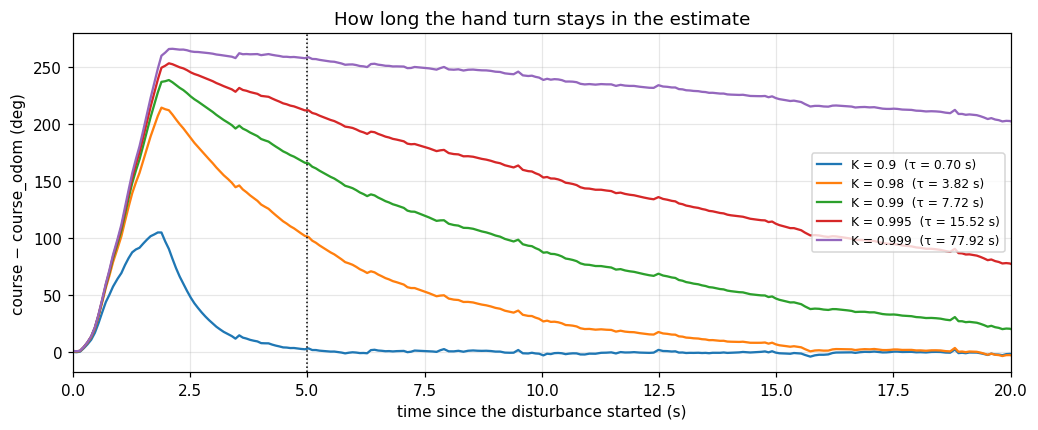

    K  tau (s)  max remembered (deg)  decay to 1/e (s)  remembered 5 s after the peak (deg)
0.900    0.702               104.811             0.857                                0.324
0.980    3.822               214.463             3.918                               61.272
0.990    7.722               237.702             8.066                              127.632
0.995   15.522               251.282            16.017                              185.742
0.999   77.922               262.818               NaN                              250.653
tau >= 5 s needs K >= 5 / (5 + dt) = 0.9846  (dt = 78 ms)


In [10]:
K1 = 0.98; df1, m1 = D[K1]
KS = [0.9, 0.98, 0.99, 0.995, 0.999]
fig, ax = plt.subplots(figsize=(11, 4))
rows = []
if DIS[K1]:
    t = df1.t_s.values; a = np.searchsorted(t, DIS[K1][0])
    for Kx in KS:
        r = courses(df1, m1, Kx)
        gap = np.degrees(r.course.values - r.course_odom.values)
        g0, t_ret, p = memory(t, gap, a)
        ax.plot(t[a:] - t[a], gap[a:], lw=1.5, label=f'K = {Kx}  (τ = {Kx * DT / (1 - Kx):.2f} s)')
        rows.append([Kx, Kx * DT / (1 - Kx), g0, t_ret, np.interp(t[p] + 5, t, gap)])
    ax.axvline(5, color='k', ls=':', lw=1)
ax.set_xlim(0, 20); ax.set_xlabel('time since the disturbance started (s)'); ax.set_ylabel('course − course_odom (deg)'); ax.legend(fontsize=8)
ax.set_title('How long the hand turn stays in the estimate'); plt.show()
W = pd.DataFrame(rows, columns=['K', 'tau (s)', 'max remembered (deg)', 'decay to 1/e (s)', 'remembered 5 s after the peak (deg)'])
print(W.round(3).to_string(index=False))
print(f'tau >= 5 s needs K >= 5 / (5 + dt) = {5 / (5 + DT):.4f}  (dt = {1000*DT:.0f} ms)')

## Summary table

In [11]:
S = M[M['x, y from'] == 'gyro'].drop(columns='x, y from').reset_index(drop=True)
S.insert(0, 'Run', [1, 2, 3]); S.insert(2, 'tau (s)', [K * DT / (1 - K) for K in S.K])
S['behaviour after the disturbance'] = [BEHAVIOUR[K] for K in S.K]
print(S.round(3).to_string(index=False))

 Run    K  tau (s)  max |distance| (cm)  RMS distance (cm)  mean |courseAngle| (deg)  final error (cm)                                                                                                                       behaviour after the disturbance
   1 0.98    3.822               36.631             16.591                    82.733            38.181 held: wheels slipped (encoders -237 deg, gyro +32 deg); after release the estimate slid to the false encoder course in ~4 s; twisted "91", ~38 cm off
   2 0.50    0.078                7.268              4.095                    11.468             8.374                         estimate = encoders (tau < one loop); encoders caught up 0.5 s after release, ~10 deg left; rest of the "91" close (7 cm max)
   3 0.02    0.002               20.406             10.383                    30.736             9.990                                             estimate = encoders; ~37 deg of the hand turn never seen; the "1" drawn rotated, 20 cm max, en

## Short analysis

**Calibration.** The two-stage calibration (3 s mean + std, then the mean of samples within 4 σ) gave
b0 = 0.070 °/s with σ = 0.056 °/s, 357 samples, none rejected. With the motors off and K = 1 the course drifted
−0.195° in 60 s = **−0.16 °/min**, well under the 1 °/min target. Over a 25 s run the gyro alone loses < 0.1°.

**What `K` really means here.** The program loop is **78 ms** (not the 10–20 ms one might expect), so
τ = K·dt/(1−K) is 3.8 s for K = 0.98, 78 ms for K = 0.5 and 1.6 ms for K = 0.02. Only run 1 has a time constant
longer than one loop. Runs 2 and 3 are therefore *almost the same filter*: in both the course is pulled back to
`course_odom` within one loop, so the gyro adds nothing. Their different outcomes come from the different hand turns
(gyro: +36° and +51°), not from the gain.

**What the robot did after the disturbance (from the logs).**
* **K = 0.98.** While the robot was held, the controller kept driving the wheels: they **slipped**, and the encoders
  counted a turn of **−237°** that never happened, while the gyro saw the real **+32°**. Right after release the
  estimate still followed the gyro (it "remembered" 215° more than the odometry), then over ≈ **4.0 s** (= τ) it slid
  to the false encoder course. The controller steered by this wrong course, so the real robot — rebuilt with the gyro
  course — drew a twisted "91" and ended **≈ 38 cm** from the target. Its own estimate drew an almost perfect "91"
  (2.6 cm): the estimate was consistent with itself but not with the world.
* **K = 0.5.** The estimate is practically the encoder course. The encoders lagged the gyro during the hold
  (−10° vs +36°) and caught up within ≈ 0.5 s after release, leaving ≈ 10°. The robot drew the rest of the "91" close
  to the reference (max 7.3 cm, end 8.4 cm). This was the best run, but by luck of the disturbance, not of the gain.
* **K = 0.02.** Again practically the encoder course. The encoders saw only +14° of a +51° turn, so **≈ 37° was never
  noticed**. The robot kept going on a rotated heading: the "1" is drawn tilted, max 20 cm, end 10 cm off.

**Wheel slip is the real enemy.** A complementary filter assumes that the odometry is *slow but honest*. Holding the
robot while the wheels turn breaks this: the slip corrupts both the path (`x, y` grow while the robot stands) and
`course_odom`. With a long τ the filter keeps the gyro's correct answer for a while but still converges to the wrong
odometry in the end — a fixed K cannot know *when* the odometry is lying.

**Choice of K.** τ ≥ 5 s at dt = 78 ms needs K ≥ 0.985; the what-if on the run-1 log shows K = 0.99 (τ = 7.7 s)
still holds 128° of the gyro information 5 s after the peak, K = 0.995 (τ = 16 s) holds 186°. Since the gyro drift
is only 0.16 °/min, for a 25 s run **K ≈ 0.995** (τ ≈ 15 s, larger than the whole manoeuvre) is the sensible
choice; the odometry is then only a weak long-term correction. A Kalman filter (or a simple gate that ignores
`course_odom` while |gyro rate − odom rate| is large) would go further: it would weight the encoders by how much they
can be trusted *right now* instead of with one fixed K.

**Geometry.** All runs used r = 4.2 cm, B = 19.4 cm (r/B = 0.2165). The gyro confirms the ratio (Lab 10: real
r/B = 0.213–0.217). The ruler values r = 3.75 cm, B = 19.6 cm (r/B = 0.191) would make `course_odom` 11 % short and
pull every K < 1 run further off; with r = 3.75 cm the effective wheel base is ≈ 17.5 cm (wheel contact points, not
the wheel centres).